<a href="https://colab.research.google.com/github/sara-abujabl25/Real_Time_Edge_Detection/blob/main/Real_Time_Edge_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Real-Time Edge Detection using OpenCV
### Sobel, Laplacian, Canny, and Filtering — Lab 2 Based

**Course:** Computer Vision: Object Detection, Motion Analysis, and Segmentation  
**Group Members:**  
1. Sarah Mousa — 202203440  
2. Layla Almoder — 202200507  
3. Wed Khalid — 202208860  



## 1. Install Required Libraries

Run this cell only if the required libraries are not already installed.

In [ ]:
# Uncomment the next line if OpenCV is not installed
# !pip install opencv-python numpy matplotlib pandas

## 2. Import Libraries and Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import time

print('OpenCV version:', cv2.__version__)

Mounted at /content/drive
OpenCV version: 5.0.0


## 3. Define Image Paths

The project instructions state that both images are stored in Google Drive → My Drive.

In [ ]:
gazelle_path = '/content/drive/MyDrive/Ghazala.jpg'
salem_path = '/content/drive/MyDrive/Salem Al-Dosari.jpg'

print('Ghazala exists:', os.path.exists(gazelle_path))
print('Salem Al-Dosari exists:', os.path.exists(salem_path))

Ghazala exists: True
Salem Al-Dosari exists: True


## 4. Load and Display the Images

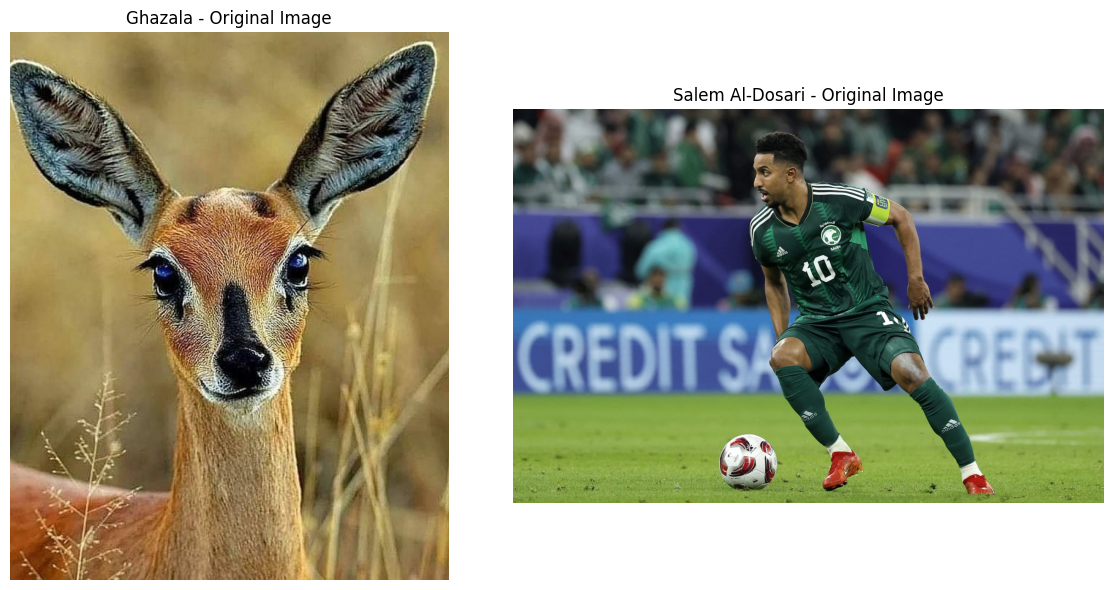

In [ ]:
def load_image(image_path):
    image = cv2.imread(image_path)

    if image is None:
        raise FileNotFoundError(
            f'{image_path} was not found. Check the Google Drive path and filename.'
        )

    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    return image, image_rgb

gazelle, gazelle_rgb = load_image(gazelle_path)
salem, salem_rgb = load_image(salem_path)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(gazelle_rgb)
plt.title('Ghazala - Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(salem_rgb)
plt.title('Salem Al-Dosari - Original Image')
plt.axis('off')

plt.tight_layout()
plt.show()

## 5. Inspect Image Information

This follows the image-information procedure used in Lab 2.

In [ ]:
def inspect_image(image, name):
    height, width, channels = image.shape

    print(name)
    print('Height:', height)
    print('Width:', width)
    print('Channels:', channels)
    print('Data type:', image.dtype)
    print('Minimum pixel value:', image.min())
    print('Maximum pixel value:', image.max())
    print()

inspect_image(gazelle, 'Ghazala')
inspect_image(salem, 'Salem Al-Dosari')

Ghazala
Height: 750
Width: 600
Channels: 3
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255

Salem Al-Dosari
Height: 1280
Width: 1920
Channels: 3
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255



## 6. Convert Images to Grayscale

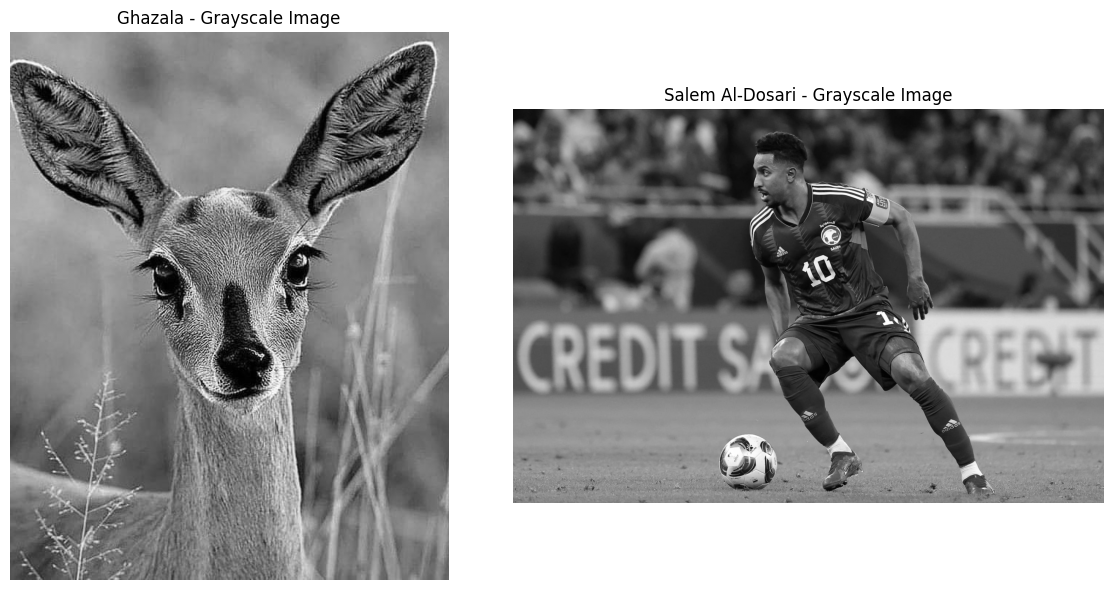

In [ ]:
gazelle_gray = cv2.cvtColor(gazelle, cv2.COLOR_BGR2GRAY)
salem_gray = cv2.cvtColor(salem, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(gazelle_gray, cmap='gray')
plt.title('Ghazala - Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(salem_gray, cmap='gray')
plt.title('Salem Al-Dosari - Grayscale Image')
plt.axis('off')

plt.tight_layout()
plt.show()

## 7. Preprocessing: Gaussian, Median, and Bilateral Filtering

The Lab 2 Gaussian filtering approach is retained. Median and bilateral filters are added because the assignment specifically requires comparison of Gaussian, median, and bilateral filtering.

Parameters:
- Gaussian: `(5, 5)`, sigma = `0`
- Median: kernel size `5`
- Bilateral: diameter `9`, sigmaColor = `75`, sigmaSpace = `75`

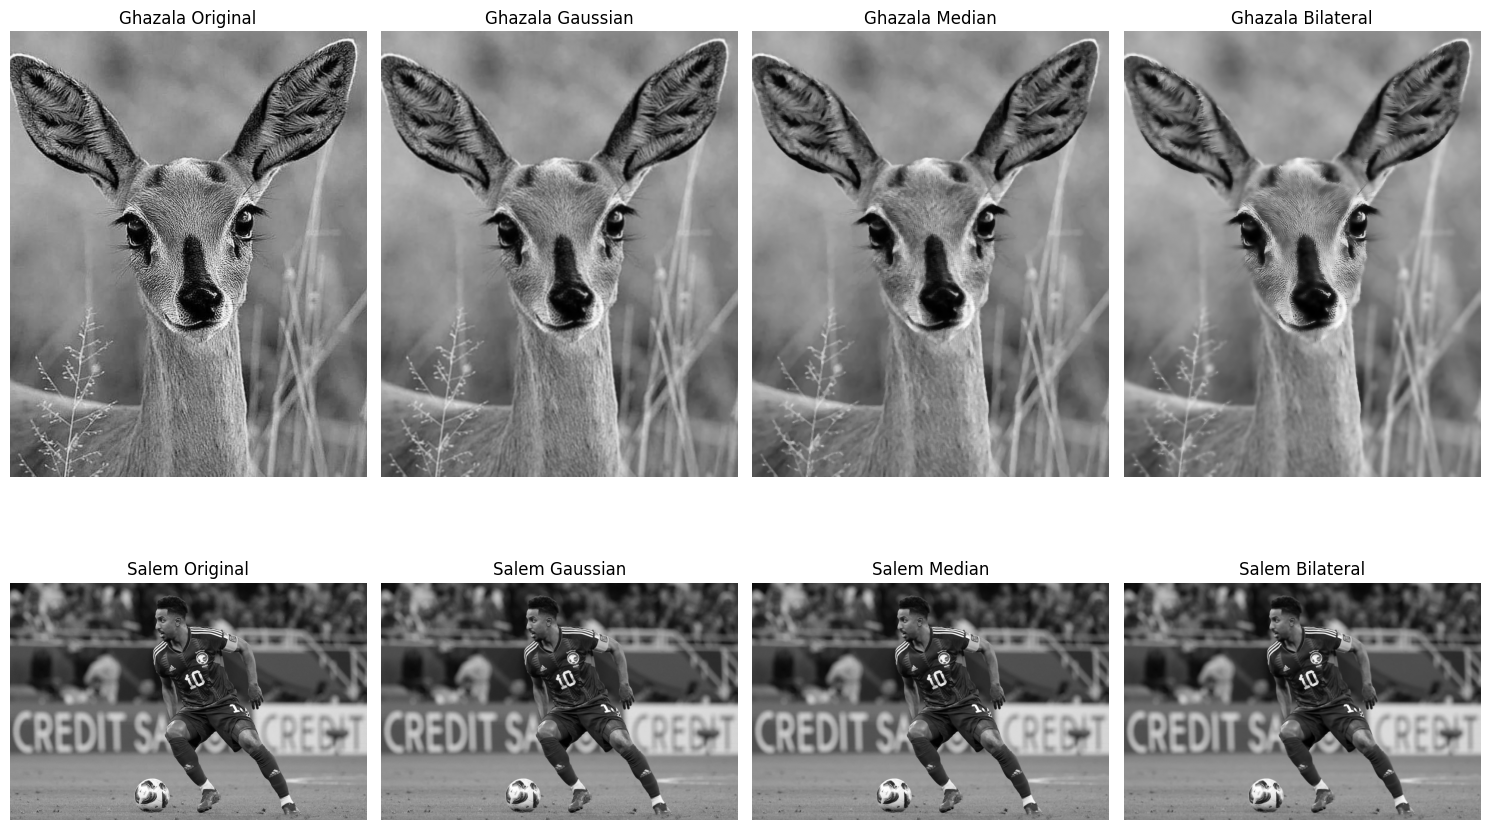

In [ ]:
def apply_filters(gray):
    gaussian_blur = cv2.GaussianBlur(gray, (5, 5), 0)
    median_blur = cv2.medianBlur(gray, 5)
    bilateral_blur = cv2.bilateralFilter(gray, 9, 75, 75)

    return gaussian_blur, median_blur, bilateral_blur

gazelle_gaussian, gazelle_median, gazelle_bilateral = apply_filters(gazelle_gray)
salem_gaussian, salem_median, salem_bilateral = apply_filters(salem_gray)

plt.figure(figsize=(15, 10))

results = [
    ('Ghazala Original', gazelle_gray),
    ('Ghazala Gaussian', gazelle_gaussian),
    ('Ghazala Median', gazelle_median),
    ('Ghazala Bilateral', gazelle_bilateral),
    ('Salem Original', salem_gray),
    ('Salem Gaussian', salem_gaussian),
    ('Salem Median', salem_median),
    ('Salem Bilateral', salem_bilateral)
]

for i, (title, result) in enumerate(results):
    plt.subplot(2, 4, i + 1)
    plt.imshow(result, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

## 8. Evaluation Metrics: PSNR and SSIM

**PSNR (Peak Signal-to-Noise Ratio)** measures the similarity between the original grayscale image and its filtered version using the mean squared error. A higher PSNR means the filtered image is numerically closer to the original.

**SSIM (Structural Similarity Index)** measures structural similarity using local luminance, contrast, and structure information. A value closer to `1` indicates greater structural similarity.

These metrics are used here to evaluate how much the preprocessing filters change the input image. They should not be interpreted as a complete measure of edge-detector quality.

In [ ]:
def calculate_ssim(image1, image2):
    image1 = image1.astype(np.float64)
    image2 = image2.astype(np.float64)

    C1 = (0.01 * 255) ** 2
    C2 = (0.03 * 255) ** 2

    mu1 = cv2.GaussianBlur(image1, (11, 11), 1.5)
    mu2 = cv2.GaussianBlur(image2, (11, 11), 1.5)

    mu1_sq = mu1 ** 2
    mu2_sq = mu2 ** 2
    mu12 = mu1 * mu2

    sigma1_sq = cv2.GaussianBlur(image1 ** 2, (11, 11), 1.5) - mu1_sq
    sigma2_sq = cv2.GaussianBlur(image2 ** 2, (11, 11), 1.5) - mu2_sq
    sigma12 = cv2.GaussianBlur(image1 * image2, (11, 11), 1.5) - mu12

    ssim_map = ((2 * mu12 + C1) * (2 * sigma12 + C2)) / (
        (mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2)
    )

    return float(ssim_map.mean())

def calculate_filter_metrics(original, filtered):
    psnr = cv2.PSNR(original, filtered)
    ssim = calculate_ssim(original, filtered)

    return psnr, ssim

## 9. Execution Time

Execution time is measured in milliseconds. It indicates how quickly a preprocessing or edge-detection operation runs on the current Colab runtime. Timing can change with hardware, runtime load, image size, and repeated execution.

In [ ]:
def measure_time(function, repeats=10):
    times = []

    for _ in range(repeats):
        start = time.perf_counter()
        function()
        end = time.perf_counter()

        times.append((end - start) * 1000)

    return np.mean(times)

## 10. Filter Comparison: PSNR, SSIM, and Time

In [ ]:
def compare_filters(gray, name):
    filters = {
        'Gaussian': lambda: cv2.GaussianBlur(gray, (5, 5), 0),
        'Median': lambda: cv2.medianBlur(gray, 5),
        'Bilateral': lambda: cv2.bilateralFilter(gray, 9, 75, 75)
    }

    rows = []

    for filter_name, function in filters.items():
        filtered = function()

        psnr, ssim = calculate_filter_metrics(gray, filtered)
        execution_time = measure_time(function)

        rows.append([
            name,
            filter_name,
            psnr,
            ssim,
            execution_time
        ])

    return rows

filter_rows = []
filter_rows.extend(compare_filters(gazelle_gray, 'Ghazala'))
filter_rows.extend(compare_filters(salem_gray, 'Salem Al-Dosari'))

filter_table = pd.DataFrame(
    filter_rows,
    columns=['Image', 'Filter', 'PSNR (dB)', 'SSIM', 'Execution Time (ms)']
)

filter_table.round(3)

,Image,Filter,PSNR (dB),SSIM,Execution Time (ms)
0,Ghazala,Gaussian,25.359,0.865,0.349
1,Ghazala,Median,22.960,0.748,1.225
2,Ghazala,Bilateral,25.090,0.766,24.215
3,Salem Al-Dosari,Gaussian,34.482,0.969,3.851
4,Salem Al-Dosari,Median,32.975,0.950,4.304
5,Salem Al-Dosari,Bilateral,33.941,0.933,223.938


## 11. Sobel Edge Detection

This section follows the Sobel implementation from Lab 2. The X and Y derivatives are calculated separately, then the gradient magnitude is calculated:

`Sobel Magnitude = sqrt(Sobel X^2 + Sobel Y^2)`

The magnitude is normalized to the range 0–255 before display, as in Lab 2.

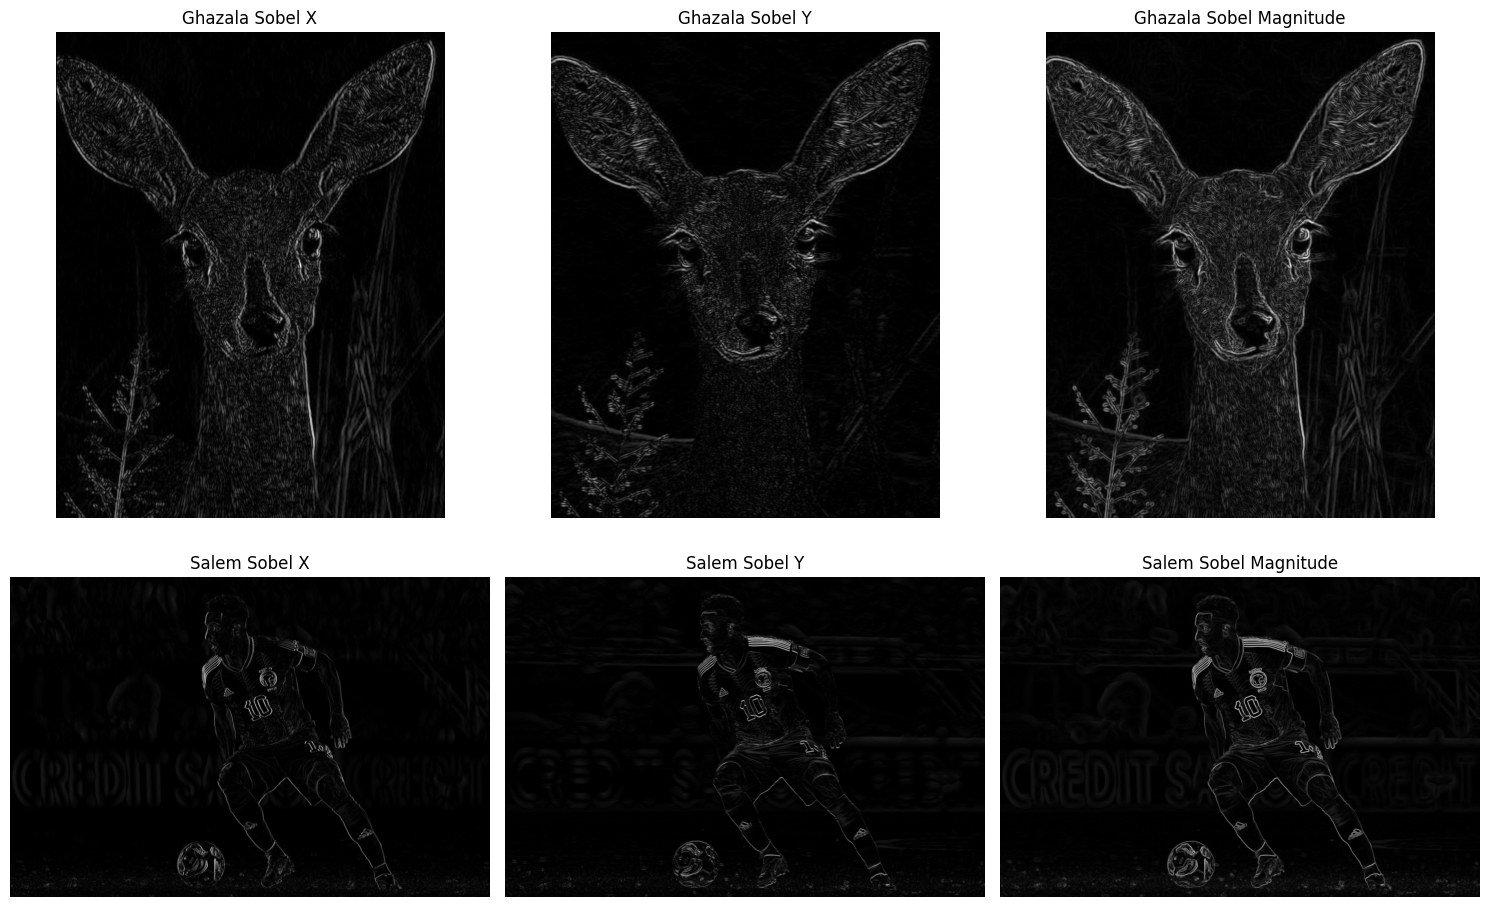

In [ ]:
def sobel_edges(gray):
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

    sobel_magnitude = np.sqrt(sobel_x ** 2 + sobel_y ** 2)

    sobel_magnitude = cv2.normalize(
        sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX
    )

    sobel_magnitude = np.uint8(sobel_magnitude)

    return sobel_x, sobel_y, sobel_magnitude

gazelle_sobel_x, gazelle_sobel_y, gazelle_sobel_magnitude = sobel_edges(gazelle_gaussian)
salem_sobel_x, salem_sobel_y, salem_sobel_magnitude = sobel_edges(salem_gaussian)

plt.figure(figsize=(15, 10))

results = [
    ('Ghazala Sobel X', np.abs(gazelle_sobel_x)),
    ('Ghazala Sobel Y', np.abs(gazelle_sobel_y)),
    ('Ghazala Sobel Magnitude', gazelle_sobel_magnitude),
    ('Salem Sobel X', np.abs(salem_sobel_x)),
    ('Salem Sobel Y', np.abs(salem_sobel_y)),
    ('Salem Sobel Magnitude', salem_sobel_magnitude)
]

for i, (title, result) in enumerate(results):
    plt.subplot(2, 3, i + 1)
    plt.imshow(result, cmap='gray')
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

## 12. Laplacian Edge Detection

The Laplacian is a second-derivative operator. The implementation follows the Lab 2 approach and uses `cv2.convertScaleAbs()` for display.

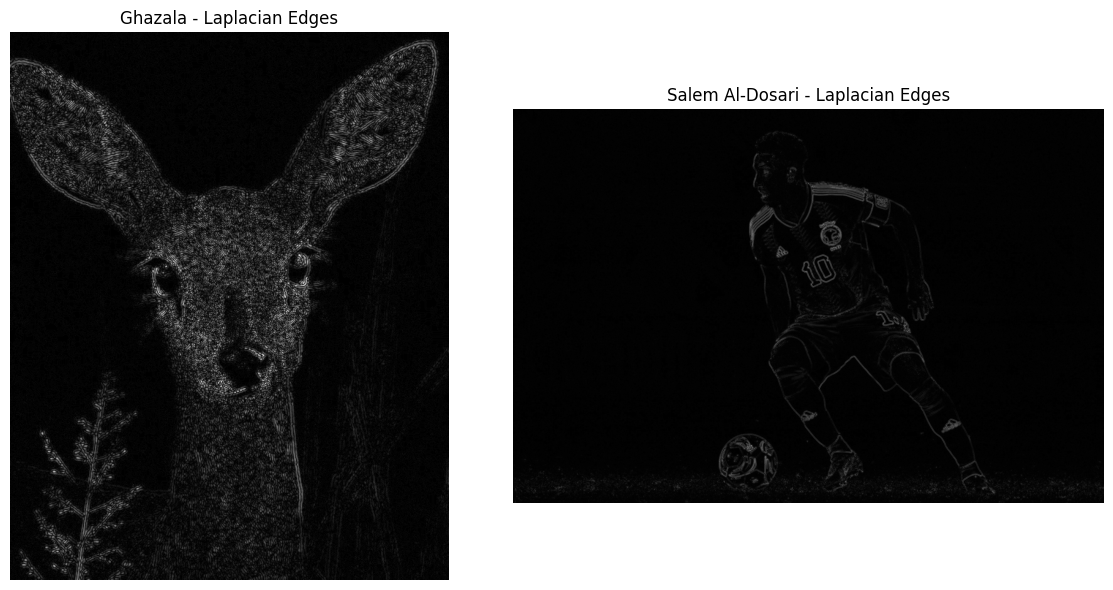

In [ ]:
gazelle_laplacian = cv2.Laplacian(gazelle_gaussian, cv2.CV_64F)
gazelle_laplacian_display = cv2.convertScaleAbs(gazelle_laplacian)

salem_laplacian = cv2.Laplacian(salem_gaussian, cv2.CV_64F)
salem_laplacian_display = cv2.convertScaleAbs(salem_laplacian)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(gazelle_laplacian_display, cmap='gray')
plt.title('Ghazala - Laplacian Edges')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(salem_laplacian_display, cmap='gray')
plt.title('Salem Al-Dosari - Laplacian Edges')
plt.axis('off')

plt.tight_layout()
plt.show()

## 13. Canny Edge Detection

Canny is included because it is explicitly required by the approved project topic. The Gaussian-filtered grayscale image is used as input, with thresholds `50` and `150`.

The method is useful for producing a thin binary edge map and is compared visually with Sobel and Laplacian.

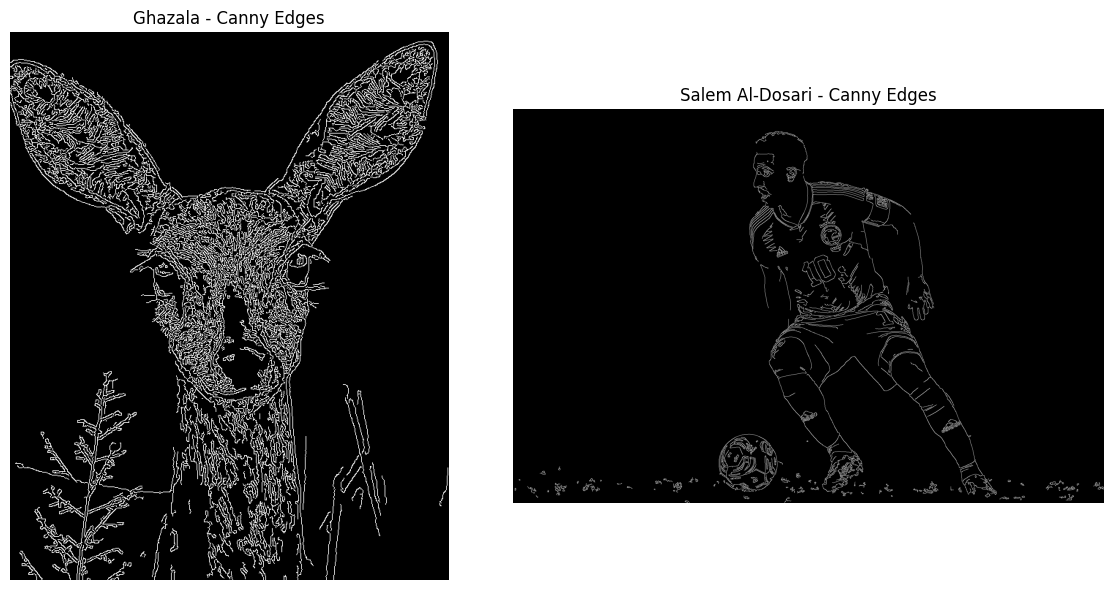

In [ ]:
gazelle_canny = cv2.Canny(gazelle_gaussian, 50, 150)
salem_canny = cv2.Canny(salem_gaussian, 50, 150)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(gazelle_canny, cmap='gray')
plt.title('Ghazala - Canny Edges')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(salem_canny, cmap='gray')
plt.title('Salem Al-Dosari - Canny Edges')
plt.axis('off')

plt.tight_layout()
plt.show()

## 14. Edge Feature Analysis

The project includes the three features requested by the professor:

1. **Edge Density:** percentage of image pixels classified as edges.
2. **Edge Strength:** mean Sobel gradient magnitude at detected edge pixels.
3. **Edge Orientation:** dominant orientation bin of the gradient directions. The orientation is calculated from `arctan2(Sobel Y, Sobel X)` and grouped into 15-degree bins between 0° and 180°.

In [ ]:
def analyze_edge_features(gray, edge_image):
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

    magnitude = np.sqrt(sobel_x ** 2 + sobel_y ** 2)
    orientation = np.degrees(np.arctan2(sobel_y, sobel_x)) % 180

    edge_mask = edge_image > 0

    edge_density = edge_mask.mean() * 100

    if np.any(edge_mask):
        edge_strength = magnitude[edge_mask].mean()

        histogram, bins = np.histogram(
            orientation[edge_mask],
            bins=np.arange(0, 181, 15)
        )

        dominant_orientation = (
            bins[np.argmax(histogram)] +
            (bins[1] - bins[0]) / 2
        )
    else:
        edge_strength = 0
        dominant_orientation = 0

    return edge_density, edge_strength, dominant_orientation

feature_rows = []

for name, gray, edges in [
    ('Ghazala', gazelle_gray, gazelle_canny),
    ('Salem Al-Dosari', salem_gray, salem_canny)
]:
    density, strength, orientation = analyze_edge_features(gray, edges)

    feature_rows.append([
        name,
        density,
        strength,
        orientation
    ])

feature_table = pd.DataFrame(
    feature_rows,
    columns=[
        'Image',
        'Edge Density (%)',
        'Edge Strength',
        'Dominant Edge Orientation (degrees)'
    ]
)

feature_table.round(3)

,Image,Edge Density (%),Edge Strength,Dominant Edge Orientation (degrees)
0,Ghazala,10.226,268.956,172.5
1,Salem Al-Dosari,1.443,328.412,52.5


## 15. Compare Sobel, Laplacian, and Canny

For each image, the three edge detectors are displayed side by side. This is the main qualitative comparison of the project.

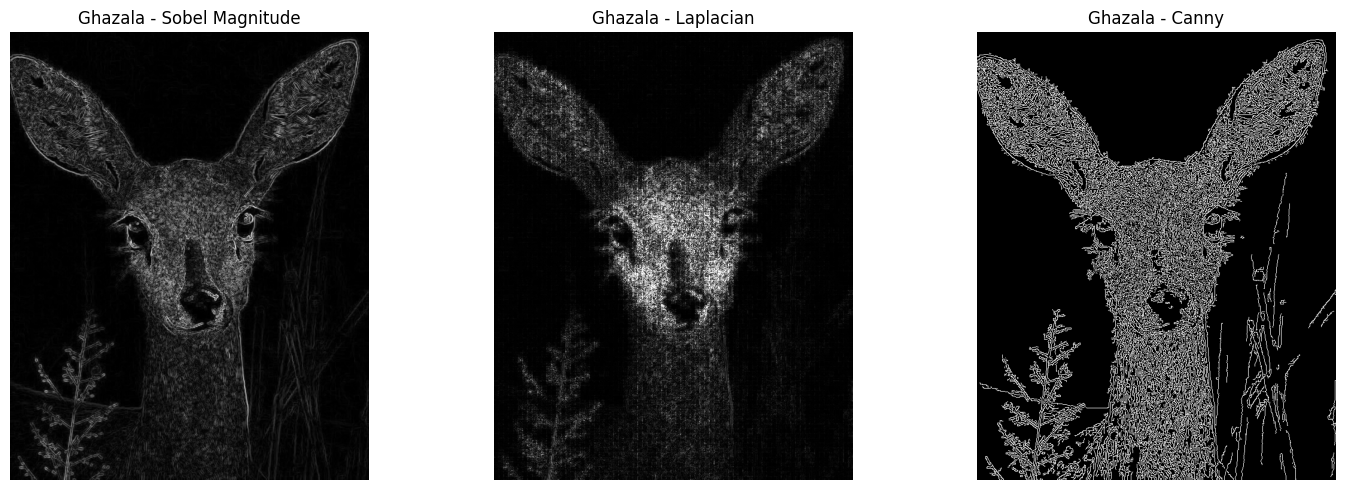

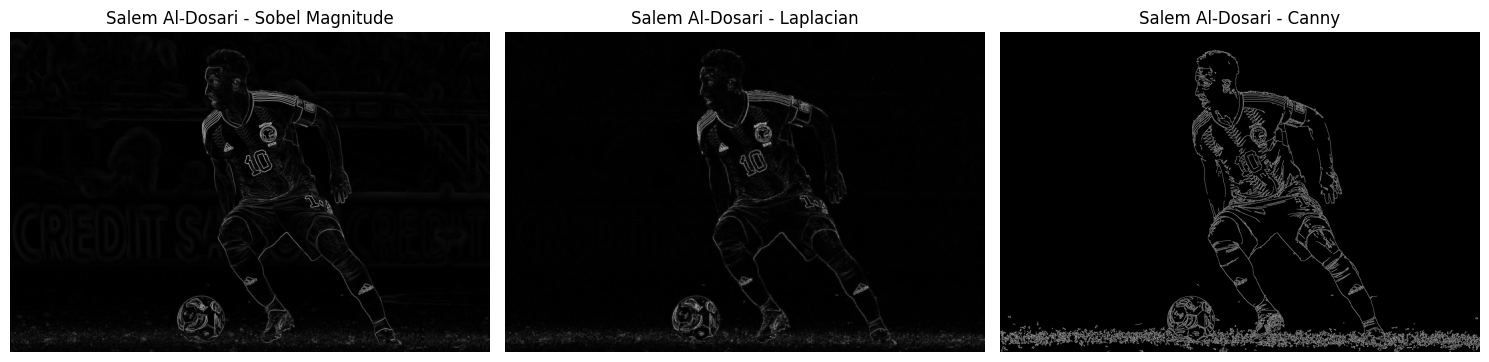

In [ ]:
def compare_edge_detectors(gray, name):
    sobel_x, sobel_y, sobel_magnitude = sobel_edges(gray)

    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    laplacian_display = cv2.convertScaleAbs(laplacian)

    canny = cv2.Canny(gray, 50, 150)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(sobel_magnitude, cmap='gray')
    plt.title(f'{name} - Sobel Magnitude')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(laplacian_display, cmap='gray')
    plt.title(f'{name} - Laplacian')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(canny, cmap='gray')
    plt.title(f'{name} - Canny')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

compare_edge_detectors(gazelle_gray, 'Ghazala')
compare_edge_detectors(salem_gray, 'Salem Al-Dosari')

## 16. Execution Time for the Edge Detectors

In [ ]:
def compare_edge_times(gray, name):
    operations = {
        'Sobel': lambda: sobel_edges(gray),
        'Laplacian': lambda: cv2.Laplacian(gray, cv2.CV_64F),
        'Canny': lambda: cv2.Canny(gray, 50, 150)
    }

    rows = []

    for operation_name, function in operations.items():
        execution_time = measure_time(function)

        rows.append([
            name,
            operation_name,
            execution_time
        ])

    return rows

edge_time_rows = []
edge_time_rows.extend(compare_edge_times(gazelle_gray, 'Ghazala'))
edge_time_rows.extend(compare_edge_times(salem_gray, 'Salem Al-Dosari'))

edge_time_table = pd.DataFrame(
    edge_time_rows,
    columns=['Image', 'Edge Detector', 'Execution Time (ms)']
)

edge_time_table.round(3)

,Image,Edge Detector,Execution Time (ms)
0,Ghazala,Sobel,6.984
1,Ghazala,Laplacian,0.839
2,Ghazala,Canny,4.423
3,Salem Al-Dosari,Sobel,36.208
4,Salem Al-Dosari,Laplacian,4.749
5,Salem Al-Dosari,Canny,15.433
